# Quantum Convolutional Kernels vs Sobel



In [ ]:
!pip -q install pennylane gdown scipy scikit-image

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 43.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 49.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 46.1 MB/s eta 0:00:00


In [ ]:
import os
import glob
import time
import random
import warnings
import cv2
import gdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pennylane as qml

from scipy.stats import wilcoxon
from sklearn.metrics import precision_recall_fscore_support, jaccard_score
from skimage.metrics import structural_similarity as ssim

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

MAX_IMAGES = 50
SIZE = 64
STRIDE = 2

FOLDER_ID = "1mxkceDypm6aFGJIBp9Y3LC--qf9MZzmv"
DATA_DIR = "/content/Dataset_Final_512"


In [ ]:
os.makedirs(DATA_DIR, exist_ok=True)

if not glob.glob(os.path.join(DATA_DIR, "*")):
    gdown.download_folder(
        id=FOLDER_ID,
        output=DATA_DIR,
        quiet=False,
        use_cookies=False,
        remaining_ok=True
    )

paths = [
    p for p in glob.glob(os.path.join(DATA_DIR, "**", "*"), recursive=True)
    if p.lower().endswith((".jpg", ".jpeg", ".png"))
]

assert paths, "No se encontraron imágenes"

rng = np.random.default_rng(SEED)
paths = list(rng.choice(paths, min(MAX_IMAGES, len(paths)), replace=False))

def load_gray(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (SIZE, SIZE))
    return img.astype(np.float32) / 255

images = [load_gray(p) for p in paths]

print(f"{len(images)} imágenes cargadas")


Retrieving folder contents


Processing file 1gjv6akrSvrwCKWiznIrGsOTLid78rqaB aug_0_DeepWater-Video1_frame_0000.jpg
Processing file 1FocMhWW0oUt4B0JoCJKZ76T8F1ZnFj7z aug_0_DeepWater-Video1_frame_0001.jpg
Processing file 1hnt6U-mS5jPBHb-h5QMC8FoKyEhwDeNZ aug_0_DeepWater-Video1_frame_0002.jpg
Processing file 1SXhSiiImqfmNNjBGPAJMGOBfq6zed-RG aug_0_DeepWater-Video1_frame_0003.jpg
Processing file 1ITwr2TtH7h6C8vTJBzaShsxF-kUktI6Y aug_0_DeepWater-Video1_frame_0004.jpg
Processing file 1wHUZik3UkPjS5IOnm58w0h9iTq4wMfat aug_0_DeepWater-Video1_frame_0005.jpg
Processing file 11mWJGKwFVrXF2RkDV23epM8Y6bhKC1QQ aug_0_DeepWater-Video1_frame_0006.jpg
Processing file 1z7f5Ve8Q2-UtFrZzycE8eWwnminfZ--B aug_0_DeepWater-Video1_frame_0007.jpg
Processing file 1qyYW6TxdR2QCjph6PTzE8w5flI1x8UDV aug_0_DeepWater-Video1_frame_0008.jpg
Processing file 1Q1189sjFmRRIQN5-8OytCdfg_k41b1j6 aug_0_DeepWater-Video1_frame_0009.jpg
Processing file 19xxUeKGnpWYH9FFzwZTsuKvWGhSHZJ5g aug_0_DeepWater-Video1_frame_0010.jpg
Processing file 1iLoZ7xi0mSBeKI_

Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1gjv6akrSvrwCKWiznIrGsOTLid78rqaB
To: /content/Dataset_Final_512/aug_0_DeepWater-Video1_frame_0000.jpg
100%|██████████| 40.1k/40.1k [00:00<00:00, 50.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1FocMhWW0oUt4B0JoCJKZ76T8F1ZnFj7z
To: /content/Dataset_Final_512/aug_0_DeepWater-Video1_frame_0001.jpg
100%|██████████| 44.9k/44.9k [00:00<00:00, 21.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1hnt6U-mS5jPBHb-h5QMC8FoKyEhwDeNZ
To: /content/Dataset_Final_512/aug_0_DeepWater-Video1_frame_0002.jpg
100%|██████████| 63.7k/63.7k [00:00<00:00, 43.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1SXhSiiImqfmNNjBGPAJMGOBfq6zed-RG
To: /content/Dataset_Final_512/aug_0_DeepWater-Video1_frame_0003.jpg
100%|██████████| 75.2k/75.2k [00:00<00:00, 54.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=1ITwr2TtH7h

50 imágenes cargadas



Download completed


In [ ]:
dev = qml.device("default.qubit", wires=4)

rngq = np.random.default_rng(SEED)
weights = rngq.uniform(-np.pi, np.pi, (2, 4, 2))

@qml.qnode(dev)
def qkernel(x):
    for i in range(4):
        qml.RY(np.pi*x[i], wires=i)
        qml.RX(np.pi*x[i]/2, wires=i)

    for layer in range(2):
        for i in range(4):
            qml.RX(weights[layer,i,0], wires=i)
            qml.RY(weights[layer,i,1], wires=i)

        qml.CNOT([0,1])
        qml.CNOT([1,2])
        qml.CNOT([2,3])
        qml.CNOT([3,0])

    return [qml.expval(qml.PauliZ(i)) for i in range(4)]

def normalize(x):
    x = x - x.min()
    return x/(x.max()+1e-8)

def sobel_edges(img):
    gx = cv2.Sobel(img, cv2.CV_32F,1,0,ksize=3)
    gy = cv2.Sobel(img, cv2.CV_32F,0,1,ksize=3)
    return normalize(cv2.magnitude(gx,gy))

def canny_reference(img):
    x = (img*255).astype(np.uint8)
    return cv2.Canny(x,80,160).astype(np.float32)/255

def binary_map(img):
    return (img > img.mean()).astype(np.uint8)

def quantum_edges(img):
    out = np.zeros_like(img)

    for y in range(0,SIZE-1,STRIDE):
        for x in range(0,SIZE-1,STRIDE):
            patch = img[y:y+2,x:x+2].flatten()
            value = np.mean(qkernel(patch))
            out[y:y+2,x:x+2] = abs(value)

    return normalize(out)


In [ ]:
records = []
outputs = []

for i,(path,img) in enumerate(zip(paths,images),1):

    ref = canny_reference(img)

    t=time.perf_counter()
    sob = sobel_edges(img)
    ts=time.perf_counter()-t

    t=time.perf_counter()
    qck = quantum_edges(img)
    tq=time.perf_counter()-t

    outputs.append((img,ref,sob,qck))

    for name,edge,sec in [
        ("Sobel",sob,ts),
        ("QCK",qck,tq)
    ]:

        pred=binary_map(edge)

        _,_,f1,_ = precision_recall_fscore_support(
            ref.ravel(),
            pred.ravel(),
            average="binary",
            zero_division=0
        )

        records.append({
            "imagen":os.path.basename(path),
            "metodo":name,
            "f1":f1,
            "iou":jaccard_score(ref.ravel(),pred.ravel(),zero_division=0),
            "ssim":ssim(ref,edge,data_range=1)
        })

    print(i,"/",len(images))

df=pd.DataFrame(records)
display(df.groupby("metodo").mean(numeric_only=True))


1 / 50
2 / 50
3 / 50
4 / 50
5 / 50
6 / 50
7 / 50
8 / 50
9 / 50
10 / 50
11 / 50
12 / 50
13 / 50
14 / 50
15 / 50
16 / 50
17 / 50
18 / 50
19 / 50
20 / 50
21 / 50
22 / 50
23 / 50
24 / 50
25 / 50
26 / 50
27 / 50
28 / 50
29 / 50
30 / 50
31 / 50
32 / 50
33 / 50
34 / 50
35 / 50
36 / 50
37 / 50
38 / 50
39 / 50
40 / 50
41 / 50
42 / 50
43 / 50
44 / 50
45 / 50
46 / 50
47 / 50
48 / 50
49 / 50
50 / 50


,f1,iou,ssim
metodo,,,
QCK,0.281504,0.166934,0.012434
Sobel,0.603295,0.440407,0.294854


In [ ]:
for metric in ["f1","iou","ssim"]:

    t=df.pivot(index="imagen",columns="metodo",values=metric).dropna()

    w,p=wilcoxon(t["Sobel"],t["QCK"])

    print(metric.upper())
    print("Sobel:",round(t["Sobel"].mean(),4))
    print("QCK:",round(t["QCK"].mean(),4))
    print("p:",p)


F1
Sobel: 0.6033
QCK: 0.2815
p: 1.7763568394002505e-15
IOU
Sobel: 0.4404
QCK: 0.1669
p: 1.7763568394002505e-15
SSIM
Sobel: 0.2949
QCK: 0.0124
p: 1.7763568394002505e-15


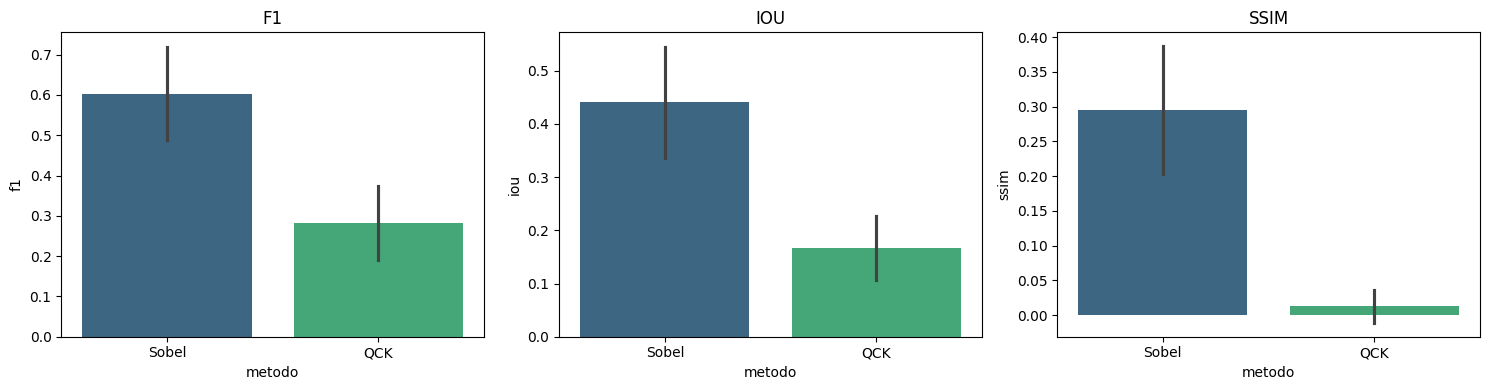

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15,4))
for a, metric in zip(ax, ["f1","iou","ssim"]):
    sns.barplot(data=df, x='metodo', y=metric, errorbar='sd', ax=a, palette='viridis')
    a.set_title(metric.upper() if metric != 'segundos' else 'Tiempo medio')
plt.tight_layout(); plt.show()

In [ ]:
os.makedirs("/content/comparaciones",exist_ok=True)

for i,(img,ref,sob,qck) in enumerate(outputs,1):

    fig,ax=plt.subplots(1,4,figsize=(12,3))

    for a,x,t in zip(
        ax,
        [img,ref,sob,qck],
        ["Original","Canny","Sobel","QCK"]
    ):
        a.imshow(x,cmap="gray")
        a.set_title(t)
        a.axis("off")

    plt.tight_layout()
    plt.savefig(f"/content/comparaciones/{i}.png",dpi=300)
    plt.close()

df.to_csv("/content/resultados_QCK_Sobel.csv",index=False)

print("Finalizado")


Finalizado


In [ ]:
import shutil
from google.colab import files

shutil.make_archive("comparaciones", "zip", "comparaciones")

files.download("comparaciones.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>